## TASK-10

## TASK-1

In [1]:

import os
import joblib
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

os.makedirs("models", exist_ok=True)
MODEL_PATH = "models/stylefind_model.joblib"

# Load Fashion-MNIST dataset
data = fetch_openml("Fashion-MNIST", version=1, as_frame=False)
X = data.data.astype(np.float32)
y = data.target.astype(int)

X_train, y_train = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

# Train and save the complete pipeline
model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("pca", PCA(n_components=50, random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ))
])

model.fit(X_train, y_train)

joblib.dump(model, MODEL_PATH)
print("Model saved successfully!")

# Load the saved model without retraining
loaded_model = joblib.load(MODEL_PATH)
predictions = loaded_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, predictions))

# Predict one image
image = X_test[0].reshape(1, -1)
prediction = loaded_model.predict(image)[0]

labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Predicted Style:", labels[prediction])


Model saved successfully!
Test Accuracy: 0.862
Predicted Style: Ankle boot


In [2]:

import time
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Load Fashion-MNIST
data = fetch_openml("Fashion-MNIST", version=1, as_frame=False)
X = data.data.astype(np.float32)
y = data.target.astype(int)

X_train, y_train = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

# Use a reproducible subset to make initial comparison faster
X_small, y_small = X_train[:10000], y_train[:10000]

def create_model(classifier):
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("pca", PCA(n_components=50, random_state=42)),
        ("classifier", classifier)
    ])

models = {
    "Logistic Regression": create_model(
        LogisticRegression(C=10, max_iter=1000)
    ),
    "KNN": create_model(
        KNeighborsClassifier(n_neighbors=9, weights="distance")
    ),
    "Random Forest": create_model(
        RandomForestClassifier(
            n_estimators=100, random_state=42, n_jobs=-1
        )
    )
}

results = []

# Compare classification models
for name, model in models.items():
    start = time.time()
    model.fit(X_small, y_small)
    training_time = time.time() - start

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Training Time (seconds)": round(training_time, 2)
    })

comparison = pd.DataFrame(results)
print("\nMODEL COMPARISON")
print(comparison.to_string(index=False))
comparison.to_csv("model_comparison.csv", index=False)

# Optimize Random Forest using GridSearchCV
rf_pipeline = create_model(
    RandomForestClassifier(random_state=42, n_jobs=-1)
)

parameters = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20]
}

search = GridSearchCV(
    rf_pipeline,
    parameters,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

search.fit(X_small, y_small)

print("\nBEST PARAMETERS:", search.best_params_)
print("BEST CROSS-VALIDATION F1:", search.best_score_)

# Retrain the optimized model on all training data
best_model = search.best_estimator_
best_model.fit(X_train, y_train)

final_predictions = best_model.predict(X_test)

print("\nOPTIMIZED RANDOM FOREST")
print("Accuracy:", accuracy_score(y_test, final_predictions))
print("Precision:", precision_score(
    y_test, final_predictions, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, final_predictions, average="macro", zero_division=0
))
print("F1 Score:", f1_score(
    y_test, final_predictions, average="macro", zero_division=0
))

# Save the optimized model
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/optimized_stylefind_model.joblib")

print("\nOptimized model saved successfully!")



MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  Training Time (seconds)
Logistic Regression    0.8207   0.820493  0.8207  0.820458                     3.84
                KNN    0.8262   0.828373  0.8262  0.826457                     0.29
      Random Forest    0.8323   0.831929  0.8323  0.831672                     1.34

BEST PARAMETERS: {'classifier__max_depth': 20, 'classifier__n_estimators': 200}
BEST CROSS-VALIDATION F1: 0.8375005342053775

OPTIMIZED RANDOM FOREST
Accuracy: 0.8601
Precision: 0.8587627388317991
Recall: 0.8600999999999999
F1 Score: 0.8587487253759999

Optimized model saved successfully!


Original features: 784
Extracted features: 50
Variance retained: 86.54 %


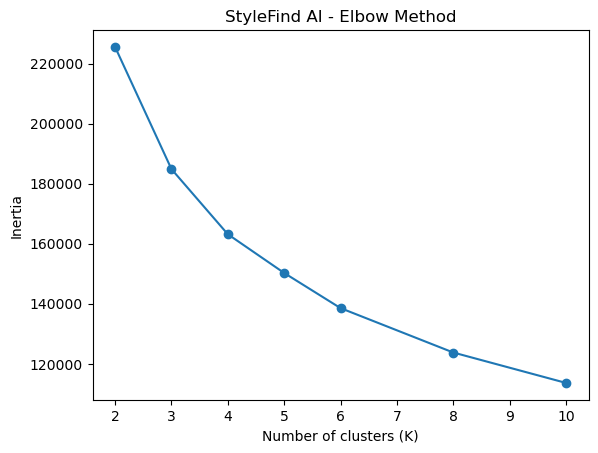


Number of clusters: 10
Silhouette Score: 0.1899

CLUSTER SUMMARY
Cluster 0 : 792 images
Cluster 1 : 492 images
Cluster 2 : 196 images
Cluster 3 : 627 images
Cluster 4 : 255 images
Cluster 5 : 765 images
Cluster 6 : 209 images
Cluster 7 : 745 images
Cluster 8 : 505 images
Cluster 9 : 414 images


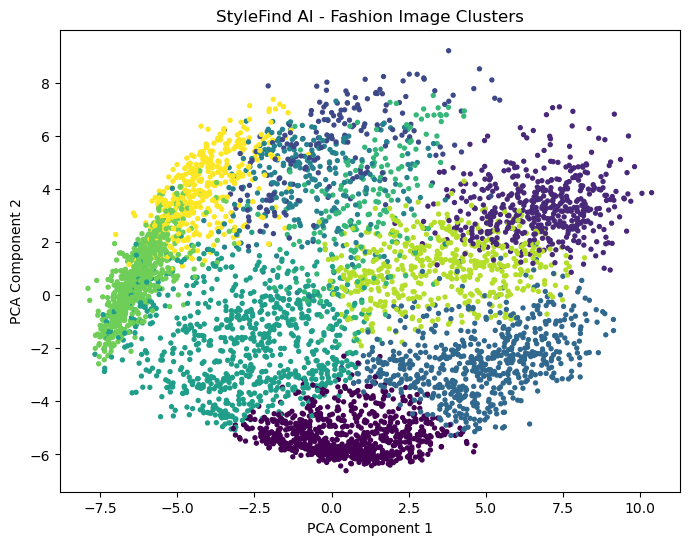


PREDICTION SUMMARY
T-shirt/top : 461
Trouser : 555
Pullover : 502
Dress : 502
Coat : 495
Sandal : 493
Shirt : 484
Sneaker : 510
Bag : 490
Ankle boot : 508

Advanced StyleFind AI workflow completed!


In [3]:

import os
import joblib
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

os.makedirs("models", exist_ok=True)

# Load Fashion-MNIST
data = fetch_openml("Fashion-MNIST", version=1, as_frame=False)
X = data.data.astype(np.float32)
y = data.target.astype(int)

# Use a smaller sample for clustering
X_sample = X[:5000]
y_sample = y[:5000]

# Preprocess images
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_sample)

# Extract 50 principal components
pca = PCA(n_components=50, random_state=42)
X_features = pca.fit_transform(X_scaled)

print("Original features:", X_sample.shape[1])
print("Extracted features:", X_features.shape[1])
print("Variance retained:", round(
    pca.explained_variance_ratio_.sum() * 100, 2
), "%")

# Find a useful number of clusters using the elbow method
k_values = [2, 3, 4, 5, 6, 8, 10]
inertias = []

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    km.fit(X_features)
    inertias.append(km.inertia_)

plt.figure()
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("StyleFind AI - Elbow Method")
plt.savefig("models/elbow_method.png")
plt.show()

# Perform K-Means clustering
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

cluster_ids = kmeans.fit_predict(X_features)

score = silhouette_score(
    X_features,
    cluster_ids,
    sample_size=1000,
    random_state=42
)

print("\nNumber of clusters:", len(np.unique(cluster_ids)))
print("Silhouette Score:", round(score, 4))

# Display the number of images in each cluster
print("\nCLUSTER SUMMARY")
for cluster in range(10):
    count = np.sum(cluster_ids == cluster)
    print("Cluster", cluster, ":", count, "images")

# Visualize the clusters in two dimensions
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_features)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_ids,
    s=8
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("StyleFind AI - Fashion Image Clusters")
plt.savefig("models/image_clusters.png")
plt.show()

# Save clustering components
joblib.dump(scaler, "models/clustering_scaler.joblib")
joblib.dump(pca, "models/clustering_pca.joblib")
joblib.dump(kmeans, "models/kmeans_model.joblib")

# Integrate the existing supervised prediction model, if available
model_path = "models/optimized_stylefind_model.joblib"

if os.path.exists(model_path):
    classifier = joblib.load(model_path)
    predictions = classifier.predict(X_sample)

    labels = [
        "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
        "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
    ]

    print("\nPREDICTION SUMMARY")
    for class_id, label in enumerate(labels):
        print(label, ":", np.sum(predictions == class_id))

print("\nAdvanced StyleFind AI workflow completed!")
